<a href="https://colab.research.google.com/github/XuningZhuang/MSSP6070/blob/main/WeeklyModules/Week08/Week_8_Exercise_Xuning_Zhuang.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata

github_token = userdata.get('6070777')
owner = 'XuningZhuang'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
!git clone {clone_url}

Cloning into 'MSSP6070'...
remote: Enumerating objects: 175, done.
remote: Counting objects: 100% (175/175), done.
remote: Compressing objects: 100% (164/164), done.
remote: Total 175 (delta 91), reused 23 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (175/175), 7.93 MiB | 6.30 MiB/s, done.
Resolving deltas: 100% (91/91), done.


In [ ]:
import pandas as pd
df = pd.read_csv('/content/MSSP6070/data/InternetSales.csv', encoding='latin-1')

/tmp/ipykernel_1421/1233392713.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/MSSP6070/data/InternetSales.csv', encoding='latin-1')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df.head()

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,2011-01-19,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,2013-01-18,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,2013-01-18,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,2013-05-03,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,2013-05-03,5/15/2013,5/10/2013


In [ ]:
yearly_sales = df.groupby(df['OrderDate'].dt.year)['SalesAmount'].sum()

print(yearly_sales)

OrderDate
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64


In [ ]:
years = np.array(yearly_sales.index)
sales = yearly_sales.values

In [ ]:
forecast_years = np.arange(years.max() + 1, years.max() + 6)
slope, intercept = np.polyfit(years, sales, 1)

In [ ]:
#To forecast
forecast_sales =intercept + slope * forecast_years

forecast = pd.Series(forecast_sales, index=forecast_years)
print(forecast)

2015    8.655907e+06
2016    9.583964e+06
2017    1.051202e+07
2018    1.144008e+07
2019    1.236814e+07
dtype: float64


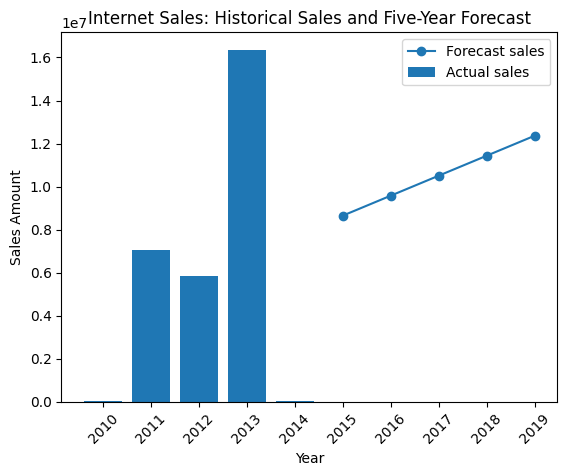

In [ ]:
plt.figure()

plt.bar(years, sales, label='Actual sales')
plt.plot(forecast_years, forecast_sales, marker='o', label='Forecast sales')

plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.title('Internet Sales: Historical Sales and Five-Year Forecast')
plt.legend()
plt.xticks(list(years) + list(forecast_years), rotation=45)

plt.show()

In [ ]:
#Top sales
product_stats = df.groupby('EnglishProductName')['SalesAmount'].agg(['count', 'sum', 'mean', 'median', 'std']).sort_values('sum', ascending=False)

print(product_stats.head())

                         count           sum         mean   median         std
EnglishProductName                                                            
Mountain-200 Black, 46     620  1.373470e+06  2215.273465  2294.99  115.188180
Mountain-200 Black, 42     614  1.363142e+06  2220.101129  2294.99  113.256820
Mountain-200 Silver, 38    596  1.339463e+06  2247.420789  2319.99  113.109387
Mountain-200 Silver, 46    580  1.301100e+06  2243.276032  2319.99  114.919793
Mountain-200 Black, 38     582  1.294866e+06  2224.855913  2294.99  111.120758


In [ ]:
top_product = product_stats.index[0]

print(top_product)

Mountain-200 Black, 46


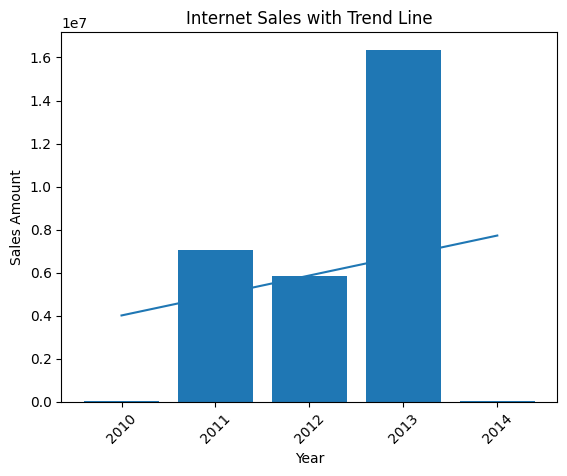

In [ ]:
# Trend line
years = np.array(yearly_sales.index)
sales = yearly_sales.values

slope, intercept = np.polyfit(years, sales, 1)

trend_line = intercept + slope * years

plt.bar(years, sales)
plt.plot(years, trend_line)

plt.xlabel('Year')
plt.ylabel('Sales Amount')
plt.title('Internet Sales with Trend Line')
plt.xticks(rotation=45)

plt.show()